# 06 · Deep Convolutional GAN (DCGAN)

**Generator:** z (100×1×1) → ConvT → 256×7×7 → ConvT → 128×14×14 → ConvT → 1×28×28 (Tanh)
**Discriminator:** 1×28×28 → Conv → 64×14×14 → Conv → 128×7×7 → Conv → 1 (logit)

**Loss:** sama dengan Vanilla GAN (BCE adversarial, generator non-saturating).

**Prinsip arsitektur DCGAN (Radford et al., 2016)** yang membuat training lebih stabil:
1. Tidak ada pooling: D memakai *strided convolution*, G memakai *transposed convolution*.
2. **BatchNorm** di G dan D (kecuali output G dan input D).
3. Tidak ada hidden layer fully-connected.
4. ReLU di G (Tanh di output), LeakyReLU(0.2) di D.
5. Bobot diinisialisasi N(0, 0.02), Adam dengan lr = 2e-4 dan β1 = 0.5.

> **Ide utama:**
> Konvolusi memberi **inductive bias** bahwa piksel yang berdekatan saling berhubungan, dan pola yang sama bisa muncul di posisi mana saja. Ini cocok dengan sifat gambar. Generator jadi lebih mudah membuat struktur lokal yang rapi, Discriminator memberi sinyal yang lebih "berguna", dan BatchNorm menjaga skala aktivasi tetap stabil. Hasilnya: **osilasi berkurang, mode collapse lebih jarang, dan gambar lebih tajam** dibanding Vanilla GAN.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
Z_DIM = 100
MAX_EPOCHS = n_epochs(30)
LEARNING_RATE = 2e-4
BETAS = (0.5, 0.999)

## 3. Model

In [4]:
def weights_init(m):
    # inisialisasi DCGAN: N(0, 0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


class Generator(nn.Module):
    def __init__(self, z_dim=100, ngf=64):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, ngf * 4, 7, 1, 0, bias=False),     # 7x7
            nn.BatchNorm2d(ngf * 4), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),   # 14x14
            nn.BatchNorm2d(ngf * 2), nn.ReLU(True),
            nn.ConvTranspose2d(ngf * 2, 1, 4, 2, 1),                     # 28x28
            nn.Tanh())

    def forward(self, z):
        return self.net(z.view(z.size(0), self.z_dim, 1, 1))


class Discriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, ndf, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True),               # 14x14
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),                              # 7x7
            nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(ndf * 2, 1, 7, 1, 0))                                            # 1x1

    def forward(self, x):
        return self.net(x).view(-1)                  # logit


G = Generator(Z_DIM).to(device)
D = Discriminator().to(device)
G.apply(weights_init)
D.apply(weights_init)

opt_G = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE, betas=BETAS)
opt_D = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE, betas=BETAS)
print(G); print(D)
print("Parameter G:", count_params(G), "| D:", count_params(D))

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(

## 4. Loss Function

`BCEWithLogits` = sigmoid + binary cross-entropy dalam satu langkah, sehingga lebih stabil secara numerik.
- `d_loss`: D belajar memberi nilai 1 untuk gambar asli dan 0 untuk gambar buatan Generator (`x_gen`).
- `g_loss_nonsat`: G belajar membuat D memberi nilai **1** untuk gambar buatannya → −log D(G(z)).
- `g_loss_sat`: bentuk minimax asli log(1 − D(G(z))). **Hanya dipakai untuk diagnosis** vanishing gradient, bukan untuk training.

In [5]:
bce = nn.BCEWithLogitsLoss()

def d_loss_fn(real_logits, gen_logits):
    return bce(real_logits, torch.ones_like(real_logits)) + bce(gen_logits, torch.zeros_like(gen_logits))

def g_loss_nonsat(gen_logits):
    return bce(gen_logits, torch.ones_like(gen_logits))            # -log D(G(z))

def g_loss_sat(gen_logits):
    return -bce(gen_logits, torch.zeros_like(gen_logits))          # log(1 - D(G(z)))

def grad_norm(params):
    return sum(p.grad.detach().pow(2).sum().item() for p in params if p.grad is not None) ** 0.5

def gradient_diagnostic(z):
    # Q3: besar gradien G untuk loss saturating vs non-saturating pada batch z yang sama (tanpa update bobot)
    out = {}
    for kind, fn in [("saturating", g_loss_sat), ("non_saturating", g_loss_nonsat)]:
        G.zero_grad(set_to_none=True)
        fn(D(G(z))).backward()
        out[kind] = grad_norm(G.parameters())
    G.zero_grad(set_to_none=True); D.zero_grad(set_to_none=True)
    return out

## 5. Training

Setiap iterasi:
1. **Update D:** maksimalkan log D(x) + log(1 − D(G(z))).
2. **Update G:** minimalkan −log D(G(z)).

Yang dicatat: loss D & G per iterasi, rata-rata D(x) dan D(G(z)) per epoch (0.5 = keseimbangan ideal), diagnosis gradien, dan *snapshot* gambar dari z yang sama di beberapa epoch (untuk melihat mode collapse).

In [6]:
g = torch.Generator(device=device).manual_seed(SEED)
fixed_z = torch.randn(16, Z_DIM, device=device, generator=g)
diag_z = torch.randn(256, Z_DIM, device=device, generator=g)

history = {"model": "dcgan", "params": count_params(G) + count_params(D), "params_G": count_params(G),
           "epoch": [], "epoch_time_s": [], "iter_d_loss": [], "iter_g_loss": [], "train": [],
           "grad_diag": [], "snapshots": {}}

for epoch in range(1, MAX_EPOCHS + 1):
    G.train(); D.train()
    t0 = time.perf_counter()
    s = {"d_loss": 0.0, "g_loss": 0.0, "D_x": 0.0, "D_G_z": 0.0}
    n = 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = to_pm1(x.to(device))
        z = torch.randn(x.size(0), Z_DIM, device=device)
        x_gen = G(z)

        # (1) update Discriminator
        real_logits, gen_logits = D(x), D(x_gen.detach())
        d_loss = d_loss_fn(real_logits, gen_logits)
        opt_D.zero_grad(); d_loss.backward(); opt_D.step()

        # (2) update Generator
        g_loss = g_loss_nonsat(D(x_gen))
        opt_G.zero_grad(); g_loss.backward(); opt_G.step()

        s["d_loss"] += d_loss.item(); s["g_loss"] += g_loss.item()
        s["D_x"] += torch.sigmoid(real_logits).mean().item()
        s["D_G_z"] += torch.sigmoid(gen_logits).mean().item()
        n += 1
        if it % 10 == 0:
            history["iter_d_loss"].append(d_loss.item())
            history["iter_g_loss"].append(g_loss.item())
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({k: v / n for k, v in s.items()})
    history["grad_diag"].append(gradient_diagnostic(diag_z))
    history["epoch"].append(epoch)
    if epoch == 1 or epoch == MAX_EPOCHS or epoch % max(1, MAX_EPOCHS // 5) == 0:
        G.eval()
        with torch.no_grad():
            history["snapshots"][str(epoch)] = to_01(G(fixed_z)).cpu().numpy().round(3).tolist()
    tr = history["train"][-1]
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] D loss: {tr['d_loss']:.3f}  G loss: {tr['g_loss']:.3f}  "
          f"D(x): {tr['D_x']:.2f}  D(G(z)): {tr['D_G_z']:.2f}  ({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"G": G.state_dict(), "D": D.state_dict()}, CKPT_DIR / "dcgan.pt")

Epoch[1/30] D loss: 0.635  G loss: 1.887  D(x): 0.76  D(G(z)): 0.25  (7.0s)
Epoch[2/30] D loss: 0.578  G loss: 1.878  D(x): 0.77  D(G(z)): 0.22  (6.5s)
Epoch[3/30] D loss: 0.820  G loss: 1.497  D(x): 0.69  D(G(z)): 0.30  (6.7s)
Epoch[4/30] D loss: 0.923  G loss: 1.342  D(x): 0.66  D(G(z)): 0.34  (6.7s)
Epoch[5/30] D loss: 0.938  G loss: 1.328  D(x): 0.66  D(G(z)): 0.34  (6.7s)
Epoch[6/30] D loss: 0.975  G loss: 1.326  D(x): 0.65  D(G(z)): 0.35  (6.8s)
Epoch[7/30] D loss: 0.979  G loss: 1.282  D(x): 0.64  D(G(z)): 0.35  (6.7s)
Epoch[8/30] D loss: 1.023  G loss: 1.252  D(x): 0.63  D(G(z)): 0.37  (6.6s)
Epoch[9/30] D loss: 1.033  G loss: 1.238  D(x): 0.63  D(G(z)): 0.37  (6.5s)
Epoch[10/30] D loss: 1.060  G loss: 1.232  D(x): 0.62  D(G(z)): 0.38  (6.4s)
Epoch[11/30] D loss: 1.062  G loss: 1.220  D(x): 0.62  D(G(z)): 0.38  (6.6s)
Epoch[12/30] D loss: 1.086  G loss: 1.212  D(x): 0.62  D(G(z)): 0.38  (6.5s)
Epoch[13/30] D loss: 1.084  G loss: 1.199  D(x): 0.61  D(G(z)): 0.38  (6.5s)
Epoch[14

## 6. Plot Loss History & Dinamika Adversarial

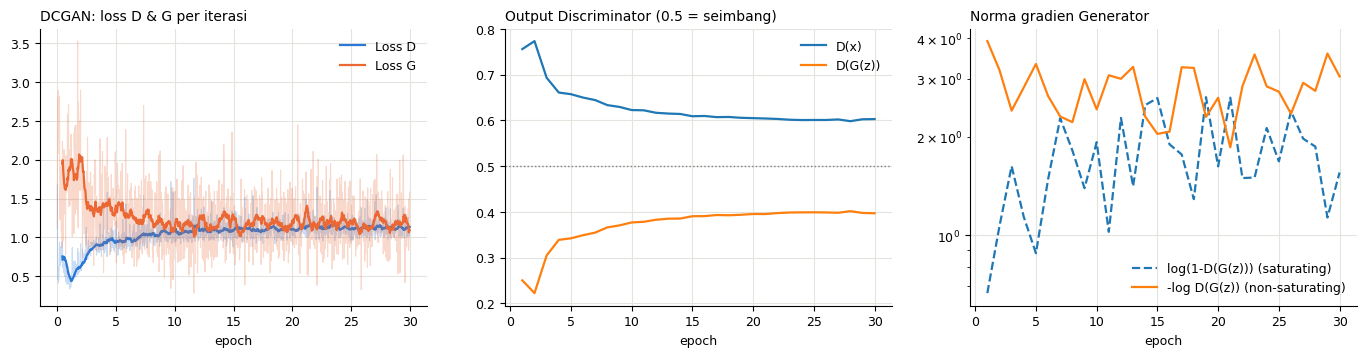

In [7]:
def moving_avg(v, k=20):
    v = np.asarray(v, float)
    return v if len(v) < k else np.convolve(v, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
per_ep = len(history["iter_d_loss"]) / len(history["epoch"])
for key, col, lab in [("iter_d_loss", "#2a78d6", "Loss D"), ("iter_g_loss", "#eb6834", "Loss G")]:
    v = np.asarray(history[key]); xs = np.arange(len(v)) / per_ep
    axes[0].plot(xs, v, color=col, alpha=0.25, lw=0.8)
    m = moving_avg(v); axes[0].plot(xs[len(xs) - len(m):], m, color=col, label=lab)
axes[0].set_title("DCGAN: loss D & G per iterasi", loc="left"); axes[0].set_xlabel("epoch"); axes[0].legend()

ep = history["epoch"]
axes[1].plot(ep, [e["D_x"] for e in history["train"]], label="D(x)")
axes[1].plot(ep, [e["D_G_z"] for e in history["train"]], label="D(G(z))")
axes[1].axhline(0.5, color="gray", ls=":", lw=1)
axes[1].set_title("Output Discriminator (0.5 = seimbang)", loc="left"); axes[1].set_xlabel("epoch"); axes[1].legend()

axes[2].plot(ep, [d["saturating"] for d in history["grad_diag"]], "--", label="log(1-D(G(z))) (saturating)")
axes[2].plot(ep, [d["non_saturating"] for d in history["grad_diag"]], label="-log D(G(z)) (non-saturating)")
axes[2].set_yscale("log"); axes[2].set_title("Norma gradien Generator", loc="left"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.show()

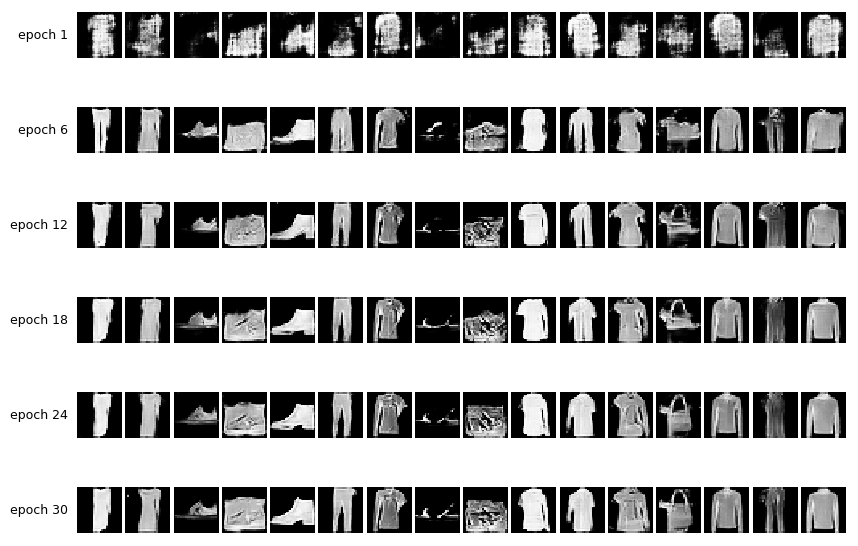

In [8]:
# Snapshot gambar dari z yang SAMA di beberapa epoch -> apakah keragamannya menyusut (mode collapse)?
snaps = history["snapshots"]
fig, axes = plt.subplots(len(snaps), 1, figsize=(10, 1.2 * len(snaps)))
for ax, (ep_k, arr) in zip(np.atleast_1d(axes), snaps.items()):
    show_imgs(ax, torch.tensor(arr), label=f"epoch {ep_k}")
plt.show()

## 7. Evaluasi: Sampling, FID, Mode Coverage, Latency

GAN tidak punya encoder, jadi **MSE/PSNR/SSIM tidak berlaku** (ditulis *N/A (Tanpa Encoder)*). Model dinilai dari sampel yang dihasilkan dari z ~ N(0, I).

FID           : 21.425387582187568
Mode coverage : {'class_hist': [0.12039999663829803, 0.11240000277757645, 0.10320000350475311, 0.09139999747276306, 0.08780000358819962, 0.10440000146627426, 0.08420000225305557, 0.10679999738931656, 0.1096000000834465, 0.07980000227689743], 'entropy_norm': 0.9964472055435181, 'modes_covered': 10}
Latency       : 1.82 ms / batch 64 | 0.50 ms / 1 sampel
Kestabilan    : {'g_loss_cv_last_half': 0.24291189323309045, 'd_loss_cv_last_half': 0.08651382765407069, 'final_D_x': 0.6027766379387411, 'final_D_G_z': 0.39687739724301857, 'label': 'Cukup stabil'}


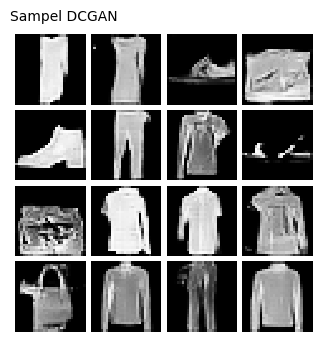

In [9]:
G.eval()
clf = load_mlp_classifier()
gen = lambda n, gen_=None: to_01(G(torch.randn(n, Z_DIM, device=device, generator=gen_)))

g = torch.Generator(device=device).manual_seed(SEED)
with torch.no_grad():
    samples = torch.cat([gen(min(500, FID_NUM_SAMPLES - i), g).cpu() for i in range(0, FID_NUM_SAMPLES, 500)])

metrics = {"model": "dcgan", "params": history["params"], "latent_dim": Z_DIM,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics["fid"] = compute_fid(samples, splits)
metrics["mode_coverage"] = mode_coverage(samples, clf)
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = measure_latency(lambda: gen(LATENCY_BATCH))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = measure_latency(lambda: gen(1))
metrics["latency_mode"] = "sampling satu langkah (single-pass)"
metrics["stability"] = stability_summary(history)
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "betas": list(BETAS),
                      "batch_size": BATCH_SIZE, "z_dim": Z_DIM}

print(f"FID           : {metrics['fid']}")
print(f"Mode coverage : {metrics['mode_coverage']}")
print(f"Latency       : {metrics['latency_ms_batch64']:.2f} ms / batch 64 | {metrics['latency_ms_batch1']:.2f} ms / 1 sampel")
print(f"Kestabilan    : {metrics['stability']}")
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel DCGAN"); plt.show()

## 8. Interpolasi Laten (Figur 4 & Q4)

GAN tidak punya encoder. Jadi z_A dan z_B dipilih dari 2.000 z acak: z yang gambarnya **paling yakin** dikenali MLP Classifier sebagai kelas A dan kelas B.

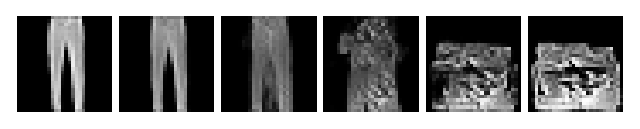

In [10]:
a, b = INTERP_CLASSES
g = torch.Generator(device=device).manual_seed(SEED)
with torch.no_grad():
    zc = torch.randn(2000, Z_DIM, device=device, generator=g)
    if clf is not None:
        pr = F.softmax(clf(to_01(G(zc))), 1)
        za, zb = zc[pr[:, a].argmax()][None], zc[pr[:, b].argmax()][None]
    else:
        za, zb = zc[:1], zc[1:2]
interp_imgs, interp_rows = interpolation_record("dcgan", za, zb, lambda z: to_01(G(z)), clf)
fig, ax = plt.subplots(figsize=(8, 1.6)); show_imgs(ax, interp_imgs); plt.show()

## 9. Simpan Hasil untuk Laporan

In [11]:
save_results("dcgan", metrics,
             artifacts={"samples16": samples[:16], "interp_imgs": interp_imgs, "interp_rows": interp_rows},
             history=history)

Hasil 'dcgan' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
